In [40]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

In [41]:
print("Loading YOLO")
net = cv2.dnn.readNetFromDarknet("yolov3 (1).cfg", "yolov3.weights")

Loading YOLO


In [42]:
classes = []
with open("coco.names", "r") as f:
    classes = [line.strip() for line in f.readlines()]

In [43]:
layer_names = net.getLayerNames()

In [44]:
output_layers = [layer_names[i - 1] for i in net.getUnconnectedOutLayers()]
print("YOLO Loaded")

YOLO Loaded


Input Image:


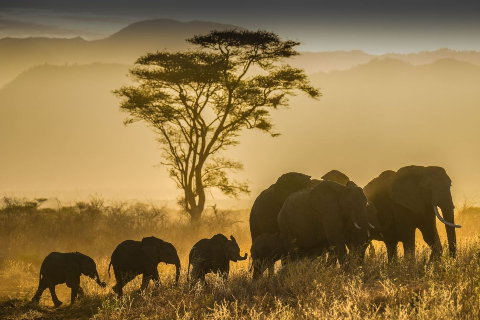

In [45]:
img = cv2.imread("wildlife-sanctuaries-across-the-world.jpg")
img = cv2.resize(img, None,
fx=0.4, fy=0.4)
height, width, channels = img.shape
print("Input Image:")
cv2_imshow(img)


In [46]:
blob = cv2.dnn.blobFromImage(img, 1/255.0, (416, 416), swapRB = True, crop=False)
net.setInput(blob)
outs = net.forward(output_layers)

In [47]:
class_ids = []
confidences = []
boxes = []
for out in outs:
    for detection in out:
        scores = detection[5:]
        class_id = np.argmax(scores)
        confidence = scores[class_id]
        if confidence > 0.3:
            center_x = int(detection[0] * width)
            center_y = int(detection[1] * height)
            w = int(detection[2] * width)
            h = int(detection[3] * height)
            x = int(center_x - w / 2)
            y = int(center_y - h / 2)
            boxes.append([x, y, w, h])
            confidences.append(float(confidence))
            class_ids.append(class_id)

In [48]:
indexes = cv2.dnn.NMSBoxes(boxes, confidences, 0.5, 0.4)

In [49]:
from re import X
colors = np.random.uniform(0, 255, size=(len(classes), 3))
for i in range(len(classes)):
  if i in indexes:
    x, y, w, h = boxes[i]
    label = str(classes[class_ids[i]])
    color = colors[class_ids[i]]
    cv2.rectangle(img, (x, y), (x + w, y + h), color, 2)
    cv2.putText(img, label, (x, y + 30), cv2.FONT_HERSHEY_PLAIN, 3, color, 3)
    print(f"Detected object:{label},confidence:{confidences[i]}, box: {x}, {y}, {w}, {h}")

Detected object:elephant,confidence:0.993423342704773, box: 249, 169, 134, 98
Detected object:elephant,confidence:0.9989187121391296, box: 363, 164, 101, 102
Detected object:elephant,confidence:0.597596287727356, box: 250, 232, 37, 44
Detected object:elephant,confidence:0.9912664294242859, box: 107, 236, 75, 60
Detected object:elephant,confidence:0.9937266111373901, box: 186, 233, 59, 51
Detected object:elephant,confidence:0.9799147248268127, box: 29, 250, 74, 58


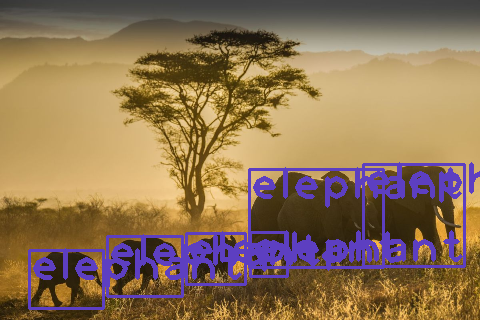

-1

In [50]:
cv2_imshow(img)
cv2.waitKey(0)